# Bài 9: Mạng nơ-ron nhiều lớp (MLP)
**Học máy ứng dụng — Trường Đại học Văn Lang, Khoa Công nghệ Thông tin**

Lời giải theo `Lab09_MLP.pdf` của ThS. Nguyễn Thái Anh. Phần A gồm **5 bước thực hành**;
phần B gồm **6 bài tập**, kèm giải thích, kiểm chứng và hình minh họa như Lab5.

**Dữ liệu:** `xor.csv`, `hai_vang_trang.csv`, `sinh_vien_mo_rong.csv`, `gia_nha.csv` và bộ chữ số load_digits.

**Cách chạy:** giải nén gói dữ liệu của lab để có `data/` cạnh notebook, rồi chọn
**Restart Kernel and Run All Cells**. Có thể đặt CSV trực tiếp cạnh notebook. Mở Jupyter từ
gốc repo hoặc thư mục lab đều được. Kết quả được nhúng trong notebook, hình lưu thêm vào `images/`.

**Cài thư viện:** `pip install numpy pandas matplotlib scikit-learn jupyter`.
Các bộ dữ liệu đóng gói trong scikit-learn không cần tải mạng. CSV/PDF/ZIP không đưa lên GitHub.

## 0. Chuẩn bị môi trường

Với thí nghiệm phân loại, chia 75% học / 25% kiểm tra với `random_state=17`, `stratify=y`, giống đề.
Chuẩn hoá được đặt trong pipeline để chỉ học thống kê từ từng tập học của CV.
Chọn tham số hoặc ngưỡng bằng tập học; tập kiểm tra dùng báo cáo các thí nghiệm đã định trong đề.
Vì cùng tập kiểm tra được dùng nhiều lần trong bài thực hành, không xem các kết quả là đánh giá
độc lập cho một hệ thống đã được lựa chọn sau nhiều thí nghiệm.

Lần kiểm tra này giới hạn BLAS/OpenMP ở 1 luồng để giảm dao động và chi phí chạy trên dữ liệu nhỏ; môi trường nhiều luồng có thể cho chênh lệch thời gian và sai số tối ưu số học.

In [1]:
from pathlib import Path
from time import perf_counter
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.datasets import load_digits
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

THU_MUC_LAB = Path('09. MLP') if Path('09. MLP').is_dir() else Path('.')
THU_MUC_ANH = THU_MUC_LAB / 'images'
THU_MUC_ANH.mkdir(exist_ok=True)


def doc_csv(ten, cot_bat_buoc):
    for p in (THU_MUC_LAB / 'data' / ten, THU_MUC_LAB / ten):
        if p.is_file():
            df = pd.read_csv(p)
            assert set(cot_bat_buoc).issubset(df.columns), f'Sai cột trong {ten}'
            assert len(df) > 0 and np.isfinite(df[cot_bat_buoc].to_numpy(dtype=float)).all(), ten
            print(f'{ten}: {df.shape[0]} dòng, {df.shape[1]} cột; không thiếu giá trị ở cột dùng')
            return df
    raise FileNotFoundError(f'Thiếu {ten}: hãy giải nén gói dữ liệu vào {THU_MUC_LAB}/data/.')


def chia(X, y):
    return train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)


def luu_hinh(ten):
    plt.savefig(THU_MUC_ANH / ten, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


def ve_bien(ax, mo_hinh, X, y, tieu_de):
    a = np.asarray(X)
    le = np.maximum(np.ptp(a, axis=0)*0.08, 0.1)
    xx, yy = np.meshgrid(np.linspace(a[:, 0].min()-le[0], a[:, 0].max()+le[0], 160),
                         np.linspace(a[:, 1].min()-le[1], a[:, 1].max()+le[1], 150))
    luoi = np.c_[xx.ravel(), yy.ravel()]
    if isinstance(X, pd.DataFrame):
        luoi = pd.DataFrame(luoi, columns=X.columns)
    zz = mo_hinh.predict(luoi).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=['#fed7d7', '#c3dafe'], alpha=0.8)
    ax.scatter(a[:, 0], a[:, 1], c=y, cmap='coolwarm_r', s=17, edgecolors='white', linewidths=0.3)
    ax.set_title(tieu_de)
    ax.set_xlabel(X.columns[0] if isinstance(X, pd.DataFrame) else 'x1')
    ax.set_ylabel(X.columns[1] if isinstance(X, pd.DataFrame) else 'x2')


plt.rcParams.update({'figure.figsize': (8, 5), 'figure.dpi': 110,
                     'font.family': 'DejaVu Sans', 'axes.grid': True, 'grid.alpha': 0.25})
print('Python', platform.python_version(), '| NumPy', np.__version__, '| pandas', pd.__version__)
print('scikit-learn', sklearn.__version__, '| matplotlib', plt.matplotlib.__version__)

Python 3.11.9 | NumPy 1.26.4 | pandas 2.3.3
scikit-learn 1.8.0 | matplotlib 3.10.8


---
# Phần A — Bài thực hành
## Bước 1 — Tự tính lan truyền tiến (Mục 2, `m1`)

Một nơ-ron tính z=xW+b rồi áp hàm kích hoạt. Với dữ liệu dạng ma trận, mỗi hàng là một mẫu,
mỗi cột của W tương ứng một nơ-ron ở lớp sau. Mạng thủ công dưới đây giải bảng XOR bit
(0,1 → 1; 1,0 → 1), dùng hai nơ-ron ReLU và đầu ra tuyến tính.

Một nơ-ron: z=1.80, sigmoid(z)=0.858149


,x1,x2,h1,h2,y
0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,1.0,0.0,1.0
2,1.0,0.0,1.0,0.0,1.0
3,1.0,1.0,2.0,1.0,0.0


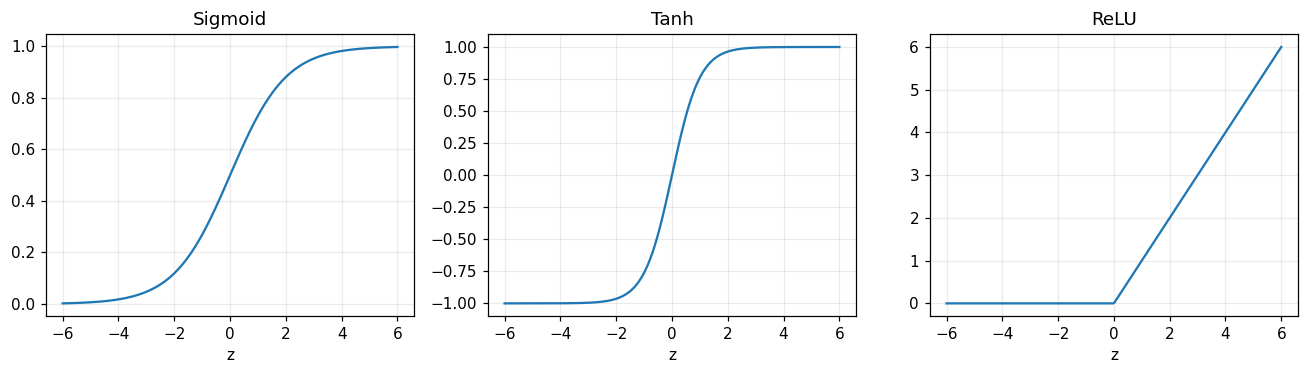

In [2]:
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import mean_absolute_error


def sigmoid(z):
    return 1/(1+np.exp(-np.clip(np.asarray(z,dtype=float),-700,700)))


def relu(z):
    return np.maximum(0,z)


def so_tham_so(mlp):
    return sum(w.size for w in mlp.coefs_)+sum(b.size for b in mlp.intercepts_)


# Giữ và báo rõ cảnh báo; không âm thầm bỏ qua các cấu hình chưa hội tụ.
nhat_ky_canh_bao=[]


def hoc(mh,X,y,ten):
    with warnings.catch_warnings(record=True) as ds:
        warnings.simplefilter('always')
        mh.fit(X,y)
    for cb in ds:
        nhat_ky_canh_bao.append({'thi_nghiem':ten,'loai':cb.category.__name__,'noi_dung':str(cb.message)})
    if ds:
        print(f'{ten}: {len(ds)} cảnh báo; xem bảng tổng hợp cuối notebook.')
    return mh


w=np.array([.8,-.5,.3]); x=np.array([2.,1.,3.]); b=-.2
z=x@w+b; print(f'Một nơ-ron: z={z:.2f}, sigmoid(z)={sigmoid(z):.6f}')
W1=np.array([[1.,1.],[1.,1.]]); b1=np.array([0.,-1.]); W2=np.array([1.,-2.]); b2=0.
X_bit=np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
H=relu(X_bit@W1+b1); Y=H@W2+b2
display(pd.DataFrame(np.c_[X_bit,H,Y],columns=['x1','x2','h1','h2','y']))
assert np.array_equal(Y,[0,1,1,0])
zz=np.linspace(-6,6,300); fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,ham,ten in zip(axes,[sigmoid,np.tanh,relu],['Sigmoid','Tanh','ReLU']):
    ax.plot(zz,ham(zz)); ax.set_title(ten); ax.set_xlabel('z')
plt.tight_layout(); luu_hinh('hinh1_ham_kich_hoat.png')

**Nhận xét từ lần chạy đã kiểm tra:** Nơ-ron đơn cho z=**1.80**, sigmoid≈**0.858149**. Mạng thủ công cho đúng [0,1,1,0] trên cả bốn đầu vào bit; đã kiểm chứng bằng assert.

**Giải thích:** h₂ chỉ bật ở đầu vào (1,1), trừ 2 khỏi h₁ để đầu ra trở về 0. Nếu bỏ hàm
kích hoạt phi tuyến, nhiều phép nhân ma trận vẫn gộp thành một biến đổi tuyến tính, không giải
được XOR. Mạng phân loại sklearn dùng sigmoid ở lớp ra nhị phân, khác đầu ra tuyến tính tự đặt.

## Bước 2 — Một lớp ẩn trên dữ liệu XOR (Mục 3, `m2`)

`xor.csv` là dữ liệu góc có nhiễu, nhãn 1 chủ yếu ở hai góc cùng dấu như mô tả trong đề.
Không áp trực tiếp trọng số dành cho các bit 0/1 ở trên lên dữ liệu này. Học mạng riêng với
ReLU mặc định, solver lbfgs, max_iter=5000. Một nơ-ron ẩn không tương đương chính xác logistic,
nhưng cả cấu hình quá nhỏ lẫn logistic đều thiếu khả năng mô tả các miền rời nhau.

xor.csv: 400 dòng, 3 cột; không thiếu giá trị ở cột dùng
Logistic kiểm tra: 0.45


,no_ron_an,so_tham_so,acc_hoc,acc_kiem_tra
0,1,5,0.6533,0.69
1,2,9,0.6533,0.69
2,4,17,0.9033,0.93
3,8,33,0.9133,0.91


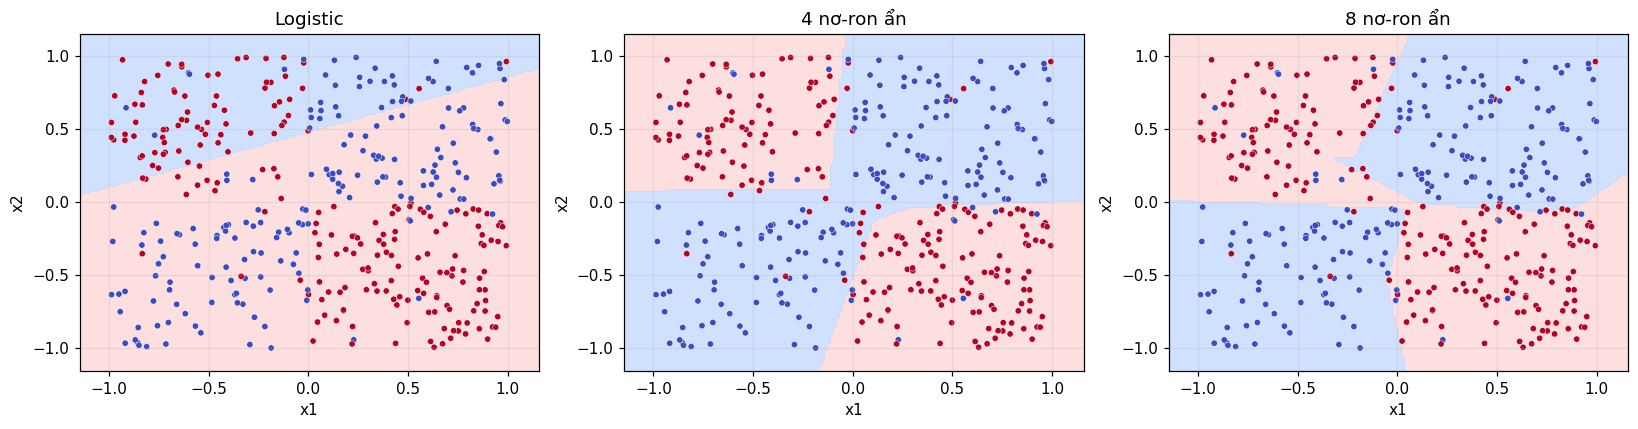

In [3]:
xor=doc_csv('xor.csv',['x1','x2','nhan']); X_xor=xor[['x1','x2']]; y_xor=xor['nhan']
Xx_tr,Xx_te,yx_tr,yx_te=chia(X_xor,y_xor)
lr_xor=LogisticRegression().fit(Xx_tr,yx_tr)
print('Logistic kiểm tra:',lr_xor.score(Xx_te,yx_te))
mang_xor={}; bang_xor=[]
for so in [1,2,4,8]:
    m=hoc(MLPClassifier(hidden_layer_sizes=(so,),solver='lbfgs',max_iter=5000,random_state=0),
          Xx_tr,yx_tr,f'XOR {so} nơ-ron')
    mang_xor[so]=m
    bang_xor.append({'no_ron_an':so,'so_tham_so':so_tham_so(m),'acc_hoc':m.score(Xx_tr,yx_tr),
                     'acc_kiem_tra':m.score(Xx_te,yx_te)})
display(pd.DataFrame(bang_xor).round(4))
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,m,ten in zip(axes,[lr_xor,mang_xor[4],mang_xor[8]],['Logistic','4 nơ-ron ẩn','8 nơ-ron ẩn']):
    ve_bien(ax,m,X_xor,y_xor,ten)
plt.tight_layout(); luu_hinh('hinh2_xor.png')

**Nhận xét từ lần chạy đã kiểm tra:** Logistic chỉ đạt **0.4500**; mạng 4 nơ-ron đạt **0.9300**, mạng 8 đạt **0.9100** trên kiểm tra. Mạng 8 có 33 tham số, nhiều hơn mạng 4 (17), nhưng không mặc định tốt hơn. Nhãn XOR trong CSV được học riêng theo đúng dữ liệu góc có nhiễu.

## Bước 3 — Độ lớn mạng và alpha (Mục 4, `m3`)

So mạng nhỏ, mạng lớn gần như không điều chuẩn và mạng lớn có L2 alpha=1. Chọn alpha bằng
CV 5 phần trên tập học. Không chọn cấu hình từ accuracy kiểm tra. Mạng lớn không tự bảo đảm
kết quả tốt hơn; quá trình tối ưu phi lồi còn phụ thuộc khởi tạo và sai số số học.

hai_vang_trang.csv: 300 dòng, 3 cột; không thiếu giá trị ở cột dùng


,mang,acc_hoc,acc_kiem_tra
0,"Nhỏ (2,), alpha=1e-4",0.8444,0.8533
1,"Lớn (100,100), alpha=1e-5",1.0000,0.7867
2,"Lớn (100,100), alpha=1",0.8711,0.9067


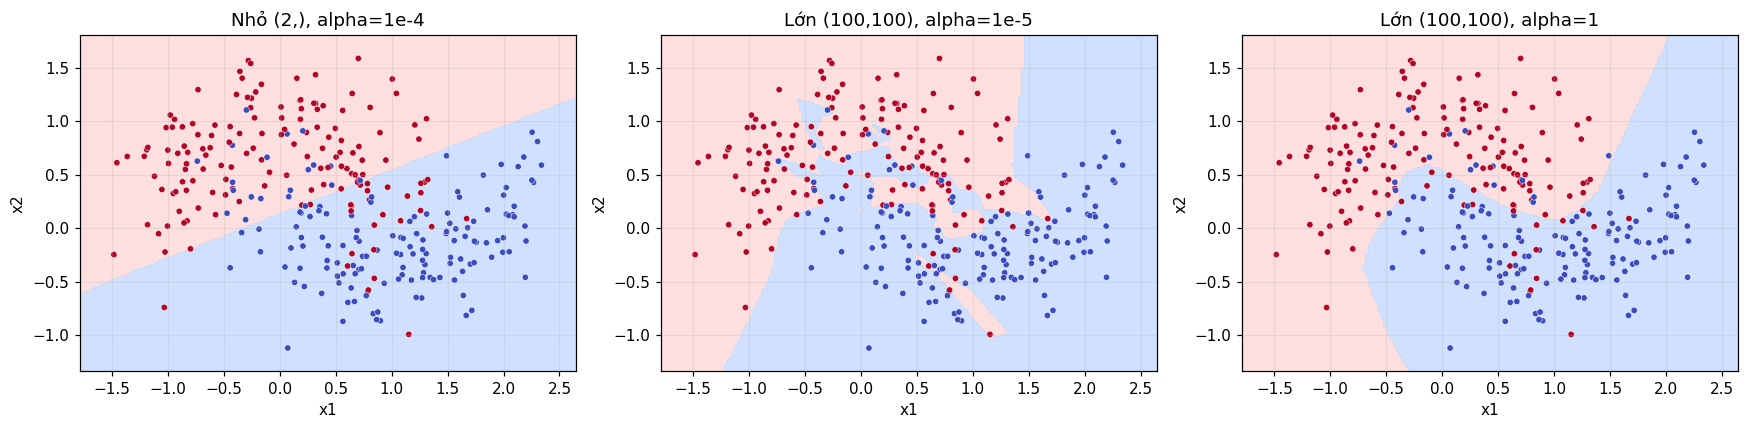

,alpha,cv_mean,cv_std,canh_bao
0,0.000,0.7778,0.0562,0
1,0.001,0.7733,0.0295,0
2,0.100,0.7733,0.0327,0
3,1.000,0.8578,0.0227,0
4,3.000,0.8444,0.0372,0
5,10.000,0.8356,0.0499,0


Alpha chọn: 1.0 ; kiểm tra: 0.9066666666666666


In [4]:
trang=doc_csv('hai_vang_trang.csv',['x1','x2','nhan']); Xt=trang[['x1','x2']]; yt=trang['nhan']
Xt_tr,Xt_te,yt_tr,yt_te=chia(Xt,yt)


def tao_mang(lop_an,alpha,activation='relu'):
    return make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=lop_an,alpha=alpha,
        activation=activation,solver='lbfgs',max_iter=20000,random_state=0))


bang_lon=[]; mang_lon={}
for ten,lop,alpha in [('Nhỏ (2,), alpha=1e-4',(2,),1e-4),
                       ('Lớn (100,100), alpha=1e-5',(100,100),1e-5),
                       ('Lớn (100,100), alpha=1',(100,100),1.)]:
    m=hoc(tao_mang(lop,alpha),Xt_tr,yt_tr,ten); mang_lon[ten]=m
    bang_lon.append({'mang':ten,'acc_hoc':m.score(Xt_tr,yt_tr),'acc_kiem_tra':m.score(Xt_te,yt_te)})
display(pd.DataFrame(bang_lon).round(4))
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,(ten,m) in zip(axes,mang_lon.items()): ve_bien(ax,m,Xt,yt,ten)
plt.tight_layout(); luu_hinh('hinh3_do_lon_va_alpha.png')
bang_alpha=[]
for alpha in [1e-5,1e-3,.1,1.,3.,10.]:
    with warnings.catch_warnings(record=True) as ds:
        warnings.simplefilter('always')
        cv=cross_val_score(tao_mang((100,100),alpha),Xt_tr,yt_tr,cv=5,scoring='accuracy',error_score='raise')
    nhat_ky_canh_bao.extend({'thi_nghiem':f'CV alpha={alpha}','loai':cb.category.__name__,'noi_dung':str(cb.message)} for cb in ds)
    bang_alpha.append({'alpha':alpha,'cv_mean':cv.mean(),'cv_std':cv.std(),'canh_bao':len(ds)})
bang_alpha=pd.DataFrame(bang_alpha); alpha_tot=float(bang_alpha.loc[bang_alpha['cv_mean'].idxmax(),'alpha'])
mang_tot=hoc(tao_mang((100,100),alpha_tot),Xt_tr,yt_tr,'Mạng alpha chọn bởi CV')
display(bang_alpha.round(4)); print('Alpha chọn:',alpha_tot,'; kiểm tra:',mang_tot.score(Xt_te,yt_te))

**Nhận xét từ lần chạy đã kiểm tra:** Mạng lớn alpha=**1e-5** đạt học **1.0000**, kiểm tra **0.7867**; alpha=**1** đạt học **0.8711**, kiểm tra **0.9067**. CV chọn alpha=1 với điểm **0.8578**. Kết quả mạng không điều chuẩn khác con số minh họa 0.7333 trong PDF, nhưng vẫn cho cùng dấu hiệu quá khớp; notebook giữ kết quả thực chạy, không sửa số cho trùng đề.

## Bước 4 — Hậu quả quên chuẩn hoá (Mục 5, `m4`)

Giữ mạng 20 nơ-ron, Adam mặc định, max_iter=3000, random_state=0. Thang chi tiêu lớn có thể
làm tối ưu khó và khiến mạng gần như chỉ dự đoán một lớp; pipeline chuẩn hoá từng đặc trưng
theo tập học giúp mô hình khai thác các cột học tập.

In [5]:
sv=doc_csv('sinh_vien_mo_rong.csv',['gio_on','diem_giua_ky','chi_tieu','qua_mon'])
Xs_tr,Xs_te,ys_tr,ys_te=chia(sv[['gio_on','diem_giua_ky','chi_tieu']],sv['qua_mon'])
bang_chuan=[]
for ten,m in [('Không chuẩn hoá',MLPClassifier(hidden_layer_sizes=(20,),max_iter=3000,random_state=0)),
               ('Có chuẩn hoá',make_pipeline(StandardScaler(),MLPClassifier(hidden_layer_sizes=(20,),max_iter=3000,random_state=0)))]:
    hoc(m,Xs_tr,ys_tr,ten); du=m.predict(Xs_te)
    bang_chuan.append({'cach':ten,'accuracy':accuracy_score(ys_te,du),'so_du_doan_qua':int(du.sum())})
display(pd.DataFrame(bang_chuan)); print('Luôn đoán qua:',ys_te.mean())

sinh_vien_mo_rong.csv: 120 dòng, 4 cột; không thiếu giá trị ở cột dùng


,cach,accuracy,so_du_doan_qua
0,Không chuẩn hoá,0.4,0
1,Có chuẩn hoá,0.9,17


Luôn đoán qua: 0.6


**Nhận xét từ lần chạy đã kiểm tra:** Không chuẩn hoá đạt **0.4000** và đoán 0 bạn qua trong 30 bạn; chuẩn hoá đạt **0.9000**, đoán 17 bạn qua. Cấu hình chưa chuẩn hoá hội tụ theo tiêu chí tối ưu nhưng đến nghiệm không hữu ích: hết cảnh báo không đồng nghĩa mô hình tốt.

## Bước 5 — Nhận dạng chữ số, số tham số và loss (Mục 6, `m5`)

Mạng 64 đầu vào, 100 nơ-ron ẩn và 10 đầu ra có 64×100+100+100×10+10=7510 tham số.
Lớp ra đa lớp dùng softmax. `loss_curve_` là mất mát huấn luyện (kèm điều chuẩn), không phải
accuracy kiểm tra. So thêm dừng sớm và các mô hình Lab6 trên cùng tập kiểm tra.

Ma trận trọng số: [(64, 100), (100, 10)] ; tham số: 7510
Số vòng: 144 ; loss đầu/vòng10/cuối: 2.5206367623245476 0.4447749037350318 0.00521015262091935
Accuracy kiểm tra: 0.9844444444444445 ; số ảnh sai: 7
Dừng sớm sau 44 vòng; accuracy: 0.9577777777777777


,mo_hinh,accuracy
0,MLP 100,0.9844
1,MLP dừng sớm,0.9578
2,Logistic,0.9711
3,KNN k=5,0.9867
4,SVM RBF,0.9911


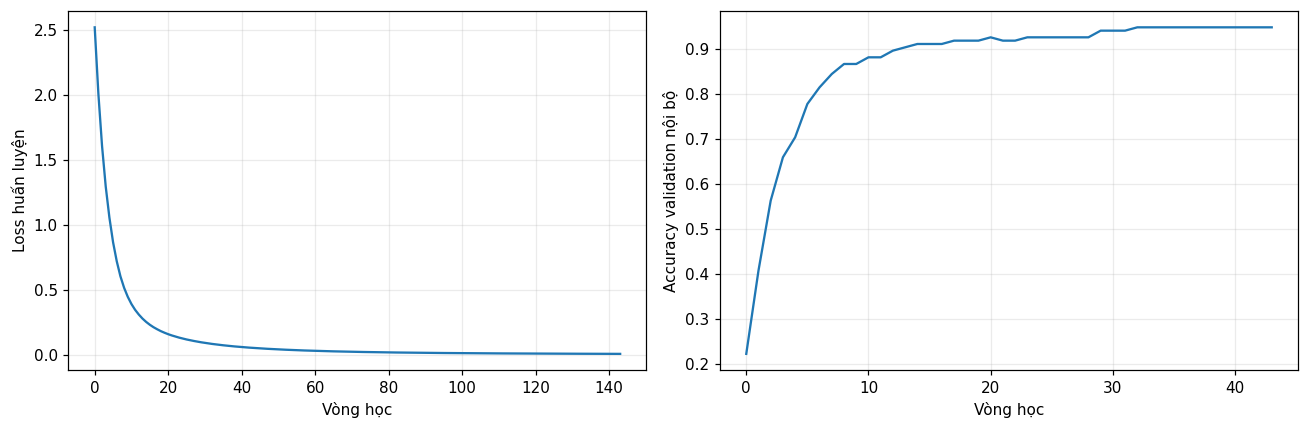

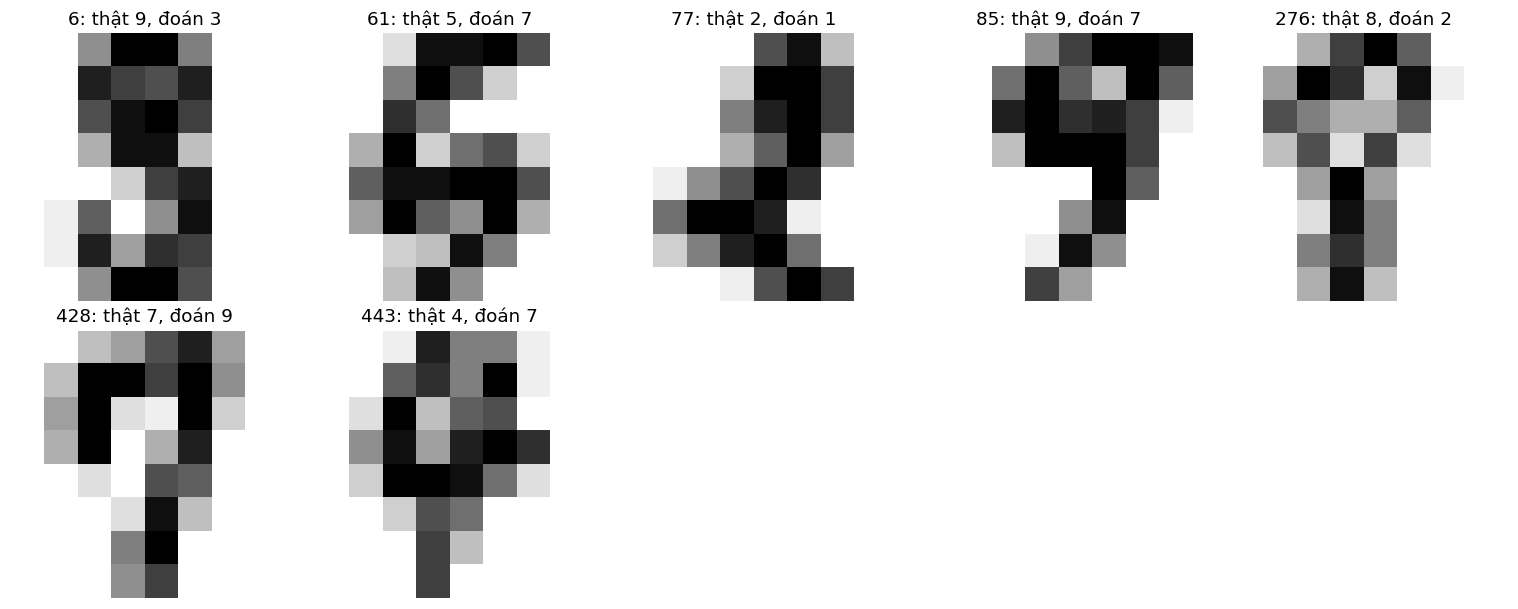

In [6]:
Xd,yd=load_digits(return_X_y=True); Xd_tr,Xd_te,yd_tr,yd_te=chia(Xd,yd)


def tao_digits(**kwargs):
    tham_so=dict(hidden_layer_sizes=(100,),max_iter=1000,random_state=0)
    tham_so.update(kwargs)
    return make_pipeline(StandardScaler(),MLPClassifier(**tham_so))


mang_digits=hoc(tao_digits(),Xd_tr,yd_tr,'Digits cơ sở'); mlp=mang_digits[-1]
du_digits=mang_digits.predict(Xd_te); sai_digits=np.flatnonzero(du_digits!=yd_te)
print('Ma trận trọng số:',[w.shape for w in mlp.coefs_],'; tham số:',so_tham_so(mlp))
print('Số vòng:',mlp.n_iter_,'; loss đầu/vòng10/cuối:',mlp.loss_curve_[0],mlp.loss_curve_[9],mlp.loss_curve_[-1])
print('Accuracy kiểm tra:',accuracy_score(yd_te,du_digits),'; số ảnh sai:',len(sai_digits))
assert so_tham_so(mlp)==7510
dung_som=hoc(tao_digits(early_stopping=True),Xd_tr,yd_tr,'Digits dừng sớm')
print('Dừng sớm sau',dung_som[-1].n_iter_,'vòng; accuracy:',dung_som.score(Xd_te,yd_te))
bang_digits=[{'mo_hinh':'MLP 100','accuracy':mang_digits.score(Xd_te,yd_te)},
             {'mo_hinh':'MLP dừng sớm','accuracy':dung_som.score(Xd_te,yd_te)}]
for ten,m in [('Logistic',make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))),
               ('KNN k=5',KNeighborsClassifier()),('SVM RBF',SVC())]:
    m.fit(Xd_tr,yd_tr); bang_digits.append({'mo_hinh':ten,'accuracy':m.score(Xd_te,yd_te)})
display(pd.DataFrame(bang_digits).round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(mlp.loss_curve_); axes[0].set_xlabel('Vòng học'); axes[0].set_ylabel('Loss huấn luyện')
axes[1].plot(dung_som[-1].validation_scores_); axes[1].set_xlabel('Vòng học'); axes[1].set_ylabel('Accuracy validation nội bộ')
plt.tight_layout(); luu_hinh('hinh4_loss_va_dung_som.png')
if len(sai_digits):
    so_cot=min(5,len(sai_digits)); so_hang=int(np.ceil(len(sai_digits)/so_cot))
    fig,axes=plt.subplots(so_hang,so_cot,figsize=(2.8*so_cot,2.8*so_hang),squeeze=False)
    for ax,i in zip(axes.flat,sai_digits):
        ax.imshow(Xd_te[i].reshape(8,8),cmap='gray_r'); ax.set_title(f'{i}: thật {yd_te[i]}, đoán {du_digits[i]}'); ax.axis('off')
    for ax in list(axes.flat)[len(sai_digits):]: ax.axis('off')
    plt.tight_layout(); luu_hinh('hinh5_chu_so_doan_sai.png')

**Nhận xét từ lần chạy đã kiểm tra:** MLP 7.510 tham số học **144 vòng**, loss **2.5206→0.00521**, đúng **443/450 ảnh (0.9844)**. Dừng sớm sau **44 vòng** đạt 0.9578; SVM đạt 0.9911. Dừng sớm tiết kiệm vòng học nhưng giảm accuracy ở cấu hình đang xét.

**Lưu ý dừng sớm:** validation nội bộ được tách trong tập học của MLP; tập kiểm tra ngoài vẫn
được giữ riêng. Trong pipeline này scaler fit trên toàn bộ tập học ngoài, gồm cả phần validation
nội bộ; điểm validation nội bộ chỉ dùng dừng sớm, không coi là một đánh giá hoàn toàn độc lập
của cả bước tiền xử lý. Không dùng điểm kiểm tra để tăng số vòng hoặc chọn seed.

---
# Phần B — Bài tập
## Bài tập 1 — Tự dự đoán bằng trọng số đã học

Dùng mạng 8 nơ-ron XOR ở phần A (không chuẩn hoá ở thí nghiệm đó), ReLU ẩn và sigmoid đầu ra.
Nếu dùng pipeline trong một bài khác, phải transform đầu vào bằng scaler đã học trước khi nhân W.

In [7]:
m8=mang_xor[8]; nam_diem=Xx_te.iloc[:5].to_numpy()
H_tay=relu(nam_diem@m8.coefs_[0]+m8.intercepts_[0])
p_tay=sigmoid(H_tay@m8.coefs_[1]+m8.intercepts_[1]).ravel()
p_sk=m8.predict_proba(Xx_te.iloc[:5])[:,1]
display(pd.DataFrame({'xac_suat_numpy':p_tay,'xac_suat_sklearn':p_sk,'chenh_tuyet_doi':abs(p_tay-p_sk)}))
print('Chênh lớn nhất:',abs(p_tay-p_sk).max()); assert np.allclose(p_tay,p_sk,atol=1e-12,rtol=1e-12)

,xac_suat_numpy,xac_suat_sklearn,chenh_tuyet_doi
0,0.018974,0.018974,3.469447e-18
1,0.999392,0.999392,0.000000e+00
2,0.792388,0.792388,0.000000e+00
3,0.136053,0.136053,0.000000e+00
4,0.956526,0.956526,0.000000e+00


Chênh lớn nhất: 3.469446951953614e-18


**Nhận xét từ lần chạy đã kiểm tra:** Chênh lớn nhất giữa xác suất lan truyền tiến NumPy và sklearn là **3.47×10⁻¹⁸**, nhỏ hơn nhiều ngưỡng kiểm tra 10⁻¹². Kết quả khớp vì dùng đúng thứ tự các lớp, bias, ReLU và sigmoid.

## Bài tập 2 — Một mạng XOR khác

$h_1=ReLU(x_1-x_2)$, $h_2=ReLU(x_2-x_1)$, y=h₁+h₂.
Một nơ-ron lấy phần dương của chênh lệch theo mỗi hướng; tổng chính là |x₁-x₂|.
Với các bit, khác nhau cho 1, bằng nhau cho 0, đúng bảng XOR.

In [8]:
h1=relu(X_bit[:,0]-X_bit[:,1]); h2=relu(X_bit[:,1]-X_bit[:,0]); y_khac=h1+h2
display(pd.DataFrame(np.c_[X_bit,h1,h2,y_khac],columns=['x1','x2','h1','h2','y']))
assert np.array_equal(y_khac,[0,1,1,0])

,x1,x2,h1,h2,y
0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,1.0,1.0
2,1.0,0.0,1.0,0.0,1.0
3,1.0,1.0,0.0,0.0,0.0


**Nhận xét từ lần chạy đã kiểm tra:** Mạng khác cũng cho đúng [0,1,1,0]. Hai nhánh tách phần dương của x₁−x₂ và x₂−x₁, tổng là |x₁−x₂|; lập luận này đúng cho bit 0/1, không tự giải toàn bộ dữ liệu góc liên tục có nhiễu.

## Bài tập 3 — So các hàm kích hoạt

Giữ hai lớp ẩn (100,100), alpha=1, scaler, lbfgs và cùng seed; lần lượt logistic, tanh, relu.
Đây là khảo sát cấu hình có sẵn theo đề. Muốn lựa chọn để triển khai phải đưa activation vào CV,
không chọn từ kết quả kiểm tra lặp lại.

In [9]:
bang_activation=[]
for ham in ['logistic','tanh','relu']:
    m=hoc(tao_mang((100,100),1.,activation=ham),Xt_tr,yt_tr,f'Activation {ham}')
    bang_activation.append({'activation':ham,'acc_hoc':m.score(Xt_tr,yt_tr),'acc_kiem_tra':m.score(Xt_te,yt_te)})
bang_activation=pd.DataFrame(bang_activation); display(bang_activation.round(4))
tot=bang_activation['acc_kiem_tra'].max()
print('Điểm kiểm tra cao nhất trong khảo sát:',bang_activation.loc[bang_activation['acc_kiem_tra']==tot,'activation'].tolist())

,activation,acc_hoc,acc_kiem_tra
0,logistic,0.8400,0.8533
1,tanh,0.8711,0.9067
2,relu,0.8711,0.9067


Điểm kiểm tra cao nhất trong khảo sát: ['tanh', 'relu']


**Nhận xét từ lần chạy đã kiểm tra:** **Tanh và ReLU cùng đạt 0.9067** trên kiểm tra; logistic activation đạt 0.8533. Không có một hàm duy nhất thắng ở khảo sát này; kết quả chỉ cho cấu hình và seed đã nêu.

## Bài tập 4 — Tốc độ học, lưu `toc_do_hoc.png`

Giữ Adam, một lớp 100 nơ-ron và max_iter=1000, đổi learning_rate_init đúng bốn mức đề yêu cầu.
Mức quá nhỏ có thể học chậm; quá lớn dễ dao động hoặc dừng ở nghiệm kém. Adam tự điều chỉnh
bước theo gradient nên không thể kết luận chỉ từ độ lớn learning_rate_init.

,learning_rate_init,n_iter,loss_cuoi,accuracy_kiem_tra
0,0.0001,582,0.018928,0.988889
1,0.0010,144,0.005210,0.984444
2,0.0100,38,0.001077,0.977778
3,0.1000,30,0.095998,0.960000


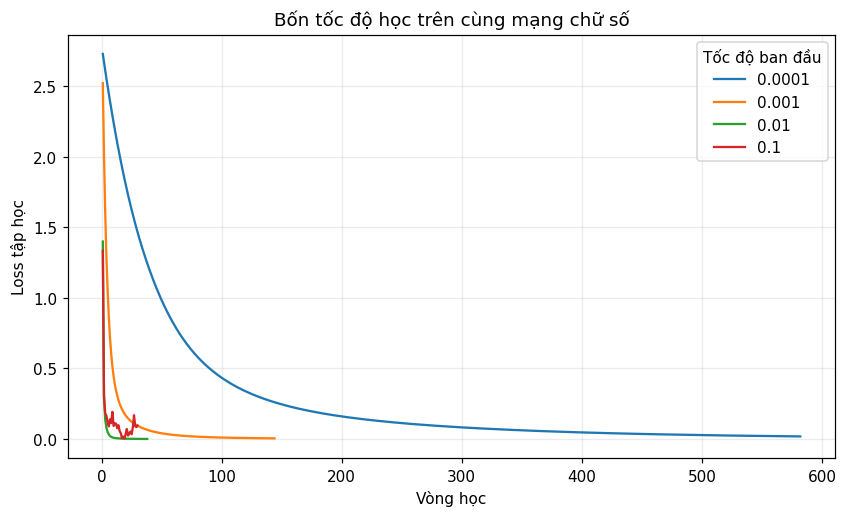

In [10]:
bang_lr=[]; plt.figure(figsize=(9,5))
for eta in [.0001,.001,.01,.1]:
    m=hoc(tao_digits(learning_rate_init=eta),Xd_tr,yd_tr,f'Learning rate {eta}')
    bang_lr.append({'learning_rate_init':eta,'n_iter':m[-1].n_iter_,'loss_cuoi':m[-1].loss_,
                    'accuracy_kiem_tra':m.score(Xd_te,yd_te)})
    plt.plot(np.arange(1,len(m[-1].loss_curve_)+1),m[-1].loss_curve_,label=str(eta))
bang_lr=pd.DataFrame(bang_lr); display(bang_lr.round(6))
plt.xlabel('Vòng học'); plt.ylabel('Loss tập học'); plt.legend(title='Tốc độ ban đầu')
plt.title('Bốn tốc độ học trên cùng mạng chữ số'); luu_hinh('toc_do_hoc.png')

**Nhận xét từ lần chạy đã kiểm tra:** Tốc độ 0.0001 cần **582 vòng**, 0.001 cần **144**, 0.01 cần **38**, 0.1 cần **30**. Mức 0.1 dừng nhanh nhưng loss 0.0960 và accuracy **0.9600**, kém mức 0.0001 (**0.9889**). Nhanh về số vòng không đồng nghĩa chất lượng tốt hơn.

## Bài tập 5 — Dò lưới mạng chữ số

12 cặp × 5 phần = 60 lượt học (cộng học lại cấu hình tốt nhất). Pipeline giữ scaler trong CV;
Adam, max_iter=1000, random_state=0. Chọn cặp theo accuracy CV; so kiểm tra với SVM RBF cùng
cách chia Lab6. Nếu hòa điểm, GridSearchCV lấy cặp xuất hiện trước trong lưới đã định.

In [11]:
tim_mlp=GridSearchCV(tao_digits(),
    {'mlpclassifier__hidden_layer_sizes':[(10,),(50,),(100,),(50,50)],
     'mlpclassifier__alpha':[.0001,.01,1.]},cv=5,scoring='accuracy',error_score='raise')
hoc(tim_mlp,Xd_tr,yd_tr,'GridSearch MLP chữ số')
bang_luoi=pd.DataFrame(tim_mlp.cv_results_)
display(bang_luoi[['param_mlpclassifier__hidden_layer_sizes','param_mlpclassifier__alpha',
                   'mean_test_score','std_test_score','rank_test_score']].sort_values('rank_test_score').round(4))
svm_so=SVC().fit(Xd_tr,yd_tr)
acc_grid=tim_mlp.score(Xd_te,yd_te); acc_svm=svm_so.score(Xd_te,yd_te)
print('Cặp tốt nhất:',tim_mlp.best_params_,'; CV:',tim_mlp.best_score_)
print('Kiểm tra MLP:',acc_grid,'; SVM:',acc_svm,'; MLP vượt SVM:',acc_grid>acc_svm)

,param_mlpclassifier__hidden_layer_sizes,param_mlpclassifier__alpha,mean_test_score,std_test_score,rank_test_score
9,"(50,)",1.0000,0.9785,0.0055,1
11,"(50, 50)",1.0000,0.9777,0.0041,2
10,"(100,)",1.0000,0.9777,0.0053,3
2,"(100,)",0.0001,0.9755,0.0080,4
5,"(50,)",0.0100,0.9755,0.0038,4
6,"(100,)",0.0100,0.9755,0.0080,4
1,"(50,)",0.0001,0.9740,0.0047,7
3,"(50, 50)",0.0001,0.9681,0.0107,8
7,"(50, 50)",0.0100,0.9681,0.0107,8
8,"(10,)",1.0000,0.9651,0.0086,10


Cặp tốt nhất: {'mlpclassifier__alpha': 1.0, 'mlpclassifier__hidden_layer_sizes': (50,)} ; CV: 0.9784689522235992
Kiểm tra MLP: 0.9822222222222222 ; SVM: 0.9911111111111112 ; MLP vượt SVM: False


**Nhận xét từ lần chạy đã kiểm tra:** CV chọn **(50,) và alpha=1**, CV **0.9785**, kiểm tra **0.9822**; **không vượt SVM 0.9911**. Cấu hình CV chọn cũng không bắt buộc đạt điểm kiểm tra cao hơn MLP cơ sở 0.9844 trên một lần chia hữu hạn.

## Bài tập 6 — MLP hồi quy

MLPRegressor một lớp 20 nơ-ron, max_iter=5000, random_state=0; chuẩn hoá đặc trưng trong pipeline.
Dùng diện tích một biến và chia 80/20, random_state=42 như Lab1/Lab5 để so công bằng với đường thẳng.
Không thay nhãn giá bằng đơn vị khác trong thí nghiệm này.

gia_nha.csv: 60 dòng, 4 cột; không thiếu giá trị ở cột dùng


,mo_hinh,MAE_ty,gia_250_m2
0,MLP,0.5008,28.1758
1,Đường thẳng,0.2578,19.9139


Miền diện tích học: 37.6 117.5


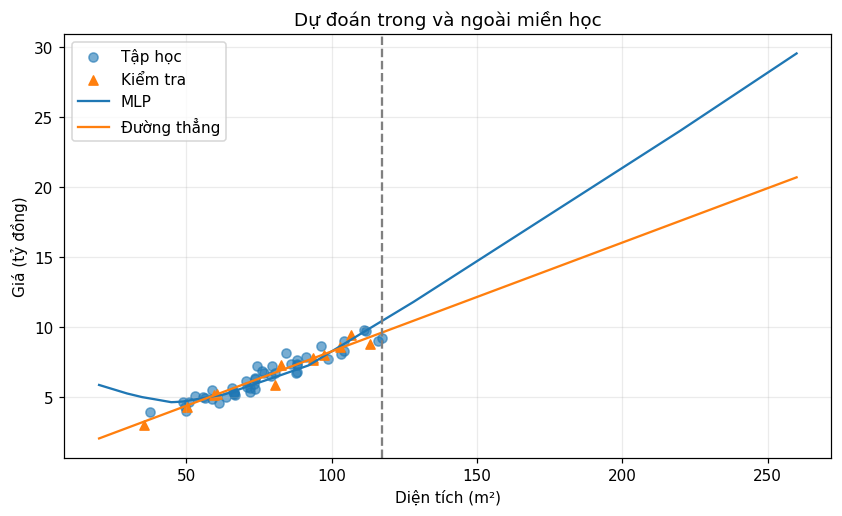

In [12]:
nha=doc_csv('gia_nha.csv',['dien_tich','gia'])
Xn_tr,Xn_te,yn_tr,yn_te=train_test_split(nha[['dien_tich']],nha['gia'],test_size=.2,random_state=42)
mlp_nha=hoc(make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(20,),max_iter=5000,random_state=0)),
            Xn_tr,yn_tr,'MLP hồi quy')
duong=LinearRegression().fit(Xn_tr,yn_tr)
can250=pd.DataFrame({'dien_tich':[250.]})
bang_nha=pd.DataFrame([{'mo_hinh':ten,'MAE_ty':mean_absolute_error(yn_te,m.predict(Xn_te)),
                        'gia_250_m2':m.predict(can250)[0]} for ten,m in [('MLP',mlp_nha),('Đường thẳng',duong)]])
display(bang_nha.round(4)); print('Miền diện tích học:',Xn_tr['dien_tich'].min(),Xn_tr['dien_tich'].max())
luoi=pd.DataFrame({'dien_tich':np.linspace(20,260,600)})
plt.figure(figsize=(9,5)); plt.scatter(Xn_tr['dien_tich'],yn_tr,label='Tập học',alpha=.6)
plt.scatter(Xn_te['dien_tich'],yn_te,label='Kiểm tra',marker='^')
for ten,m in [('MLP',mlp_nha),('Đường thẳng',duong)]: plt.plot(luoi['dien_tich'],m.predict(luoi),label=ten)
plt.axvline(Xn_tr['dien_tich'].max(),linestyle='--',color='gray'); plt.xlabel('Diện tích (m²)'); plt.ylabel('Giá (tỷ đồng)')
plt.title('Dự đoán trong và ngoài miền học'); plt.legend(); luu_hinh('hinh6_mlp_hoi_quy.png')

**Nhận xét từ lần chạy đã kiểm tra:** MLP có MAE **0.5008 tỷ**, kém hồi quy tuyến tính **0.2578 tỷ**. Căn 250 m² được MLP dự đoán **28.1758 tỷ**, đường thẳng **19.9139 tỷ**; miền học chỉ 37.6–117.5 m². Không có giá thật của căn 250 m² để xác nhận mô hình nào ngoại suy đúng, nhưng chênh lệch lớn cho thấy dự đoán phụ thuộc giả định mô hình.

**Giải thích:** mạng ReLU hồi quy có thể cho giá tiếp tục tăng ngoài miền học; điều này khác cây
và rừng hồi quy, vốn trả trung bình tại lá. Nhưng độ dốc ngoài miền là hệ quả của trọng số và các
ReLU đang bật, không được dữ liệu ngoài miền ràng buộc. Không thể kết luận MLP ngoại suy tốt chỉ
từ MAE của tập kiểm tra trong miền hoặc từ dự đoán một căn 250 m²; đường thẳng phù hợp hơn khi
giả định xu hướng tuyến tính được chấp nhận. Cả hai đều cần kiểm chứng bằng dữ liệu ngoài miền.

## Kiểm tra cảnh báo và khả năng tái lập

Không giấu ConvergenceWarning. Các cấu hình chưa hội tụ phải được nêu khi đọc bảng; max_iter
cao không bảo đảm tối ưu toàn cục. Sai khác BLAS, phiên bản và độ chính xác số có thể làm kết quả
MLP khác đề dù dùng cùng seed, đặc biệt với lbfgs và ReLU tại điểm gãy.

In [13]:
print('Tổng cảnh báo được ghi nhận:',len(nhat_ky_canh_bao))
if nhat_ky_canh_bao:
    bang_cb=pd.DataFrame(nhat_ky_canh_bao)
    display(bang_cb.groupby(['thi_nghiem','loai','noi_dung'],dropna=False).size().rename('so_lan').reset_index())
    for noi_dung in bang_cb['noi_dung'].unique(): print(noi_dung)
else:
    print('Không có cảnh báo hội tụ hoặc cảnh báo khác trong các lượt fit/CV.')

Tổng cảnh báo được ghi nhận: 0
Không có cảnh báo hội tụ hoặc cảnh báo khác trong các lượt fit/CV.
